# FinanzFair V0 — Mortgage Rate & Negotiation Intelligence

**Real-data research environment.** This notebook demonstrates the end-to-end V0 pipeline on
**real** published data, with a single, clearly-labelled semi-synthetic layer.

### Design contract

| Layer | Source | Status |
|---|---|---|
| Market state $Market_t$ | ECB Data Portal (German MIR rate, policy rate, €STR, AAA yields) | **REAL** |
| Realized pricing surface | HMDA loan-level (CFPB/FFIEC): rate spread, income, LTV, DTI, term, lender | **REAL** |
| Bank offers | thebanks.eu scraper (German lenders, append-only snapshots) | **REAL** |
| Borrower covariates $X$ | HMDA rows (→ PHF/HFCS when provided) | **REAL** |
| Empirical room $\Delta_{max}$ | HMDA spread dispersion (room to aggressive pricing) | **REAL** |
| **Extracted fraction of $\Delta_{max}$** | Richards response over counteroffer strength | **SEMI-SYNTHETIC** |

The only generated quantity is *how much of the empirically feasible room a negotiation extracts*,
as a function of counteroffer strength. It always carries `label_source='synthetic'`. Everything the
rate level is built from is real. The final product output is a **distribution** of the achievable
final rate per bank, ranked by expected final rate with an uncertainty penalty — **not** by nominal discount.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

from finanzfair.ingest import ecb, hmda, scraper
from finanzfair import pricing, population, banks, negotiation, product, evaluate
from finanzfair.config import RunContext
RUN = RunContext(seed=1)
print("Run context:", RUN.as_dict())

Run context: {'seed': 1, 'simulation_version': 'v0.1.0', 'model_version': 'v0.1.0', 'market_snapshot_version': 'v0.1.0', 'borrower_dist_version': 'phf_proxy_v0.1.0'}


## 1. Real market state — ECB Data Portal

Point-in-time German mortgage-rate benchmark by fixation bucket, the ECB policy rate, €STR and the
euro-area AAA yield curve. Cached append-only per fetch date so the snapshot is reproducible.

In [2]:
market = ecb.build_market_panel(ecb.fetch_market_series(start="2015-01"))
mrow = ecb.latest_market_row(market)
benchmark = float(mrow["de_mortgage_rate_all_irf"])
fix_bench = {5: float(mrow.get("de_mortgage_rate_1to5y", benchmark)),
             10: float(mrow["de_mortgage_rate_5to10y"]),
             15: float(mrow["de_mortgage_rate_over10y"]),
             20: float(mrow["de_mortgage_rate_over10y"]),
             30: float(mrow["de_mortgage_rate_over10y"])}
print(f"Latest German mortgage benchmark (all IRF): {benchmark:.2f}%  |  as of {mrow['month']}")
print("Fixation term structure:", {k: round(v,2) for k,v in fix_bench.items()})
market.tail(4)[["month","de_mortgage_rate_all_irf","ecb_deposit_facility","estr","ea_aaa_10y","curve_2y10y"]]

Latest German mortgage benchmark (all IRF): 4.00%  |  as of 2026-10
Fixation term structure: {5: 4.03, 10: 3.81, 15: 4.04, 20: 4.04, 30: 4.04}


,month,de_mortgage_rate_all_irf,ecb_deposit_facility,estr,ea_aaa_10y,curve_2y10y
42,2026-07,3.93,2.25,2.184,3.227314,0.466528
43,2026-08,4.00,2.25,2.185,3.339594,0.483576
44,2026-09,4.00,2.50,2.437,3.581657,0.422487
45,2026-10,4.00,2.50,2.442,3.369406,0.385945


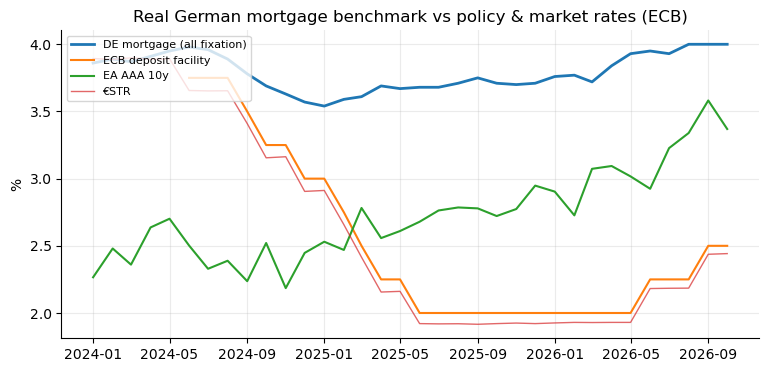

In [3]:
m = market.dropna(subset=["de_mortgage_rate_all_irf"]).copy()
x = pd.PeriodIndex(m["month"], freq="M").to_timestamp()
fig, ax = plt.subplots()
ax.plot(x, m["de_mortgage_rate_all_irf"], label="DE mortgage (all fixation)", lw=2)
ax.plot(x, m["ecb_deposit_facility"], label="ECB deposit facility", lw=1.5)
ax.plot(x, m["ea_aaa_10y"], label="EA AAA 10y", lw=1.5)
ax.plot(x, m["estr"], label="€STR", lw=1, alpha=0.7)
ax.set_title("Real German mortgage benchmark vs policy & market rates (ECB)")
ax.set_ylabel("%"); ax.legend(loc="upper left", fontsize=8); plt.show()

## 2. Real realized-pricing surface — HMDA

We model the **benchmark-relative** rate (`rate_spread` = APR − APOR), which transfers across markets far
better than the absolute US level. Quantile gradient boosting gives $Q_{10}/Q_{50}/Q_{90}$ of the borrower
spread. This answers the question that replaces invented labels: *for comparable borrowers, what spread did
they actually obtain?* (CatBoost is the production swap; sklearn quantile GBMs are used here for a
dependency-light build.)

In [4]:
raw = hmda.fetch_hmda(years=[2023], states=["DC","MD","VA"], actions=(1,))
clean = hmda.clean_hmda(raw)
print(f"Real HMDA originated loans: {len(clean):,}")
surface = pricing.EmpiricalPricingSurface().fit(clean)
print(f"Surface trained on {surface.n_train_:,} loans | population median spread = {surface.population_median_spread_:.3f} pp")
clean[["interest_rate","rate_spread","income_eur_proxy","ltv","dti","term_years"]].describe().round(2)

Real HMDA originated loans: 230,497


Surface trained on 230,497 loans | population median spread = 0.320 pp


,interest_rate,rate_spread,income_eur_proxy,ltv,dti,term_years
count,230497.00,230497.00,230497.00,230497.00,230497.00,230351.00
mean,7.01,0.50,154112.22,77.83,38.71,27.97
std,1.41,1.00,126848.04,20.38,9.86,6.14
min,1.74,-1.00,10000.00,1.62,20.00,0.08
25%,6.12,-0.16,82000.00,68.99,33.00,30.00
50%,6.75,0.32,122000.00,80.00,40.00,30.00
75%,7.50,0.94,183000.00,95.00,46.00,30.00
max,12.00,3.00,2000000.00,100.00,60.00,40.00


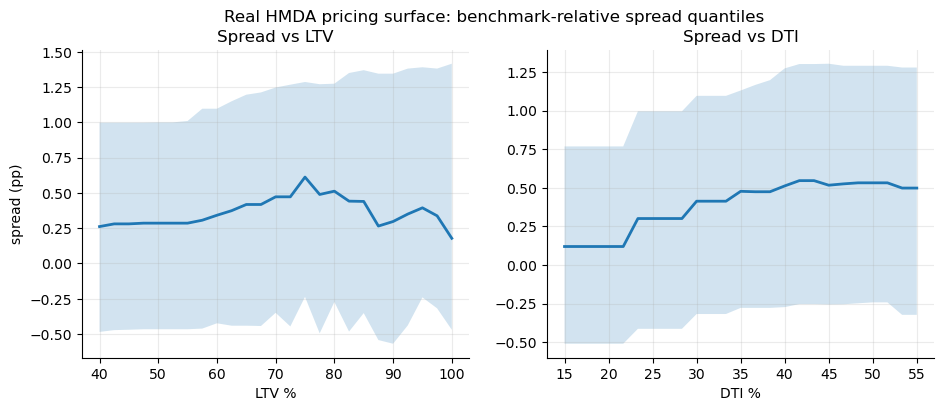

In [5]:
# How the modelled spread responds to LTV and DTI (hold others at the median).
base = clean[["ltv","dti","income_eur_proxy","loan_amount","term_years"]].median()
def surf_curve(var, grid):
    rows = pd.DataFrame([base]*len(grid)); rows[var]=grid
    rows["loan_purpose_label"]="purchase"
    return surface.predict_spread_quantiles(rows)
fig, axes = plt.subplots(1,2, figsize=(11,4))
g_ltv=np.linspace(40,100,25); q=surf_curve("ltv",g_ltv)
axes[0].fill_between(g_ltv,q.spread_q10,q.spread_q90,alpha=0.2); axes[0].plot(g_ltv,q.spread_q50,lw=2)
axes[0].set_title("Spread vs LTV"); axes[0].set_xlabel("LTV %"); axes[0].set_ylabel("spread (pp)")
g_dti=np.linspace(15,55,25); q=surf_curve("dti",g_dti)
axes[1].fill_between(g_dti,q.spread_q10,q.spread_q90,alpha=0.2); axes[1].plot(g_dti,q.spread_q50,lw=2)
axes[1].set_title("Spread vs DTI"); axes[1].set_xlabel("DTI %")
plt.suptitle("Real HMDA pricing surface: benchmark-relative spread quantiles"); plt.show()

## 3. Real bank offers — FinanzFair scraper

Live German advertised offers, stored append-only. `BankSpread(b) = advertised_rate(b) − benchmark(t)`.

In [6]:
offers = scraper.scrape_and_store()
if offers is None or offers.empty:
    offers = scraper.load_snapshots()
bank_spreads = banks.bank_spreads_from_offers(offers, benchmark_rate=benchmark)
print(f"{len(bank_spreads)} German banks, {offers['bank_id'].nunique()} unique in latest snapshot")
bank_spreads.sort_values("bank_spread_bp").round(3)

8 German banks, 8 unique in latest snapshot


,bank_id,bank_name,bank_spread_bp,bank_rate,rate_min,rate_max,bank_rate_percentile,n_offers
6,sparda_bank_muenchen_eg,Sparda-Bank München eG,-0.755,3.245,2.95,3.54,0.125,1
5,psd_bank_nord_eg,PSD Bank Nord eG,-0.660,3.340,3.08,3.60,0.250,1
7,sparda_bank_nuernberg_eg,SPARDA-BANK NÜRNBERG eG,-0.640,3.360,3.15,3.57,0.375,1
1,frankfurter_sparkasse,Frankfurter Sparkasse,-0.090,3.910,3.81,4.01,0.500,1
3,open_account,Open Account,0.073,4.073,3.44,4.53,0.625,6
4,psd_bank_hessen_thueringen_eg,PSD Bank Hessen-Thüringen eG,0.285,4.285,3.72,4.85,0.750,1
0,bnp_paribas_s_a_niederlassung_deutschland,BNP Paribas S.A. Niederlassung Deutschland,0.290,4.290,3.66,4.92,0.875,1
2,ing_diba_ag,ING-DiBa AG,0.425,4.425,4.07,4.78,1.000,1


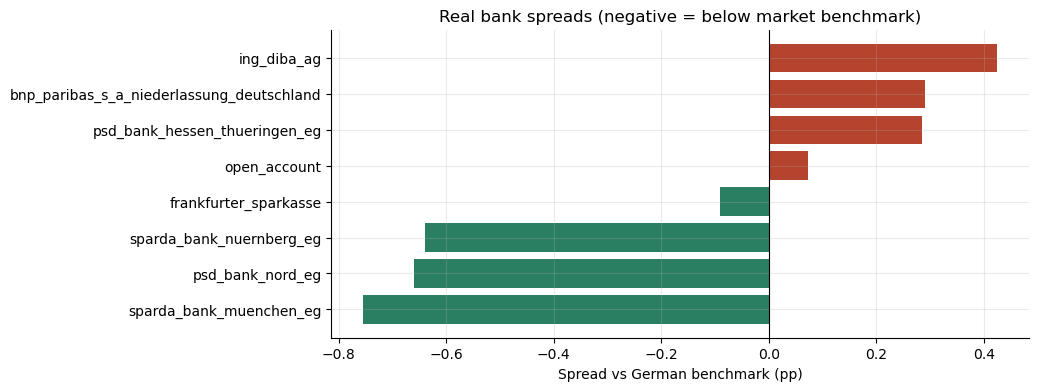

In [7]:
bs = bank_spreads.sort_values("bank_spread_bp")
colors = ["#2a7f62" if v<0 else "#b4442e" for v in bs["bank_spread_bp"]]
fig, ax = plt.subplots(figsize=(9,4))
ax.barh(bs["bank_id"], bs["bank_spread_bp"], color=colors)
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Spread vs German benchmark (pp)")
ax.set_title("Real bank spreads (negative = below market benchmark)"); plt.show()

## 4. Real borrower population + initial-rate assembly

Borrower covariates are real HMDA rows mapped to the product schema. (`credit_quality` is a transparent
composite of real affordability fields — a documented proxy until SCHUFA/credit score arrives via
PHF/HFCS/NSMO/Freddie; `fixed_period_years` is a product input, not an HMDA attribute.)

The initial rate decomposes into real components, and the empirical $\Delta_{max}$ caps any reduction at
what real dispersion supports:
$$R^{initial} = benchmark(fixation,t) + bank\_spread(b) + borrower\_center(X), \qquad
\Delta_{max} = \text{room to aggressive (Q10) pricing}.$$

In [8]:
profiles = population.profiles_from_hmda(clean, n=2500, fixed_period_years=10, seed=RUN.seed)
initial = pricing.assemble_initial_rates(profiles, surface, bank_spreads, benchmark, fix_bench)
initial = pricing.empirical_floor(initial)
print(f"(borrower × bank) rows: {len(initial):,}")
print(f"Initial median rate range: {initial.r_initial_q50.min():.2f}% – {initial.r_initial_q50.max():.2f}%")
print(f"Empirical Δmax (bp): mean {initial.delta_max.mean()*100:.1f}, p90 {initial.delta_max.quantile(0.9)*100:.1f}")
# Section-11 style box for one borrower/bank.
ex = initial.iloc[0]
print(f"\nExample — {ex.bank_id}\n  Initial (median)   {ex.r_initial_q50:.2f}%\n"
      f"  Aggressive floor   {ex.r_floor:.2f}%\n  Room (Δmax)        {ex.delta_max*100:.1f} bp")

(borrower × bank) rows: 20,000
Initial median rate range: 2.06% – 5.74%
Empirical Δmax (bp): mean 37.3, p90 40.0

Example — bnp_paribas_s_a_niederlassung_deutschland
  Initial (median)   4.27%
  Aggressive floor   3.87%
  Room (Δmax)        40.0 bp


## 5. The one semi-synthetic layer — negotiation response

Counteroffer strength $C = R^{initial}(b) - R^{best\ comparable}$ is **real** (cross-bank). The generated
part is only the extracted fraction $g(C)\in[0,1]$ of the real $\Delta_{max}$, plus a hurdle
$p=P(\Delta>0)$. We also keep the known counterfactual $\mu(c,x)=E[\Delta\mid C=c,x]$ for evaluation.

In [9]:
theta = 5.0  # selection-bias level
initial_c = negotiation.apply_selection_bias(initial, profiles, theta=theta, seed=RUN.seed)
panel = initial_c.merge(profiles[["borrower_id","LTV","DTI","gross_household_income"]], on="borrower_id")
dgp = negotiation.NegotiationDGP(family="richards", selection_bias=theta, seed=RUN.seed)
bank_params = dgp.sample_bank_params(sorted(panel.bank_id.unique()))
sim = dgp.simulate(panel, bank_params)
print(f"label_source: {sim.label_source.unique()}  |  synthetic_version: {sim.synthetic_version.iloc[0]}")
print(f"P(Δ>0) mean {np.mean(sim.true_delta>0):.2f}  |  E[Δ] {sim.true_delta.mean()*100:.1f} bp  |  median room {sim.delta_max.median()*100:.1f} bp")

label_source: ['synthetic']  |  synthetic_version: neg_dgp_v0.1.0
P(Δ>0) mean 0.78  |  E[Δ] 25.1 bp  |  median room 40.0 bp


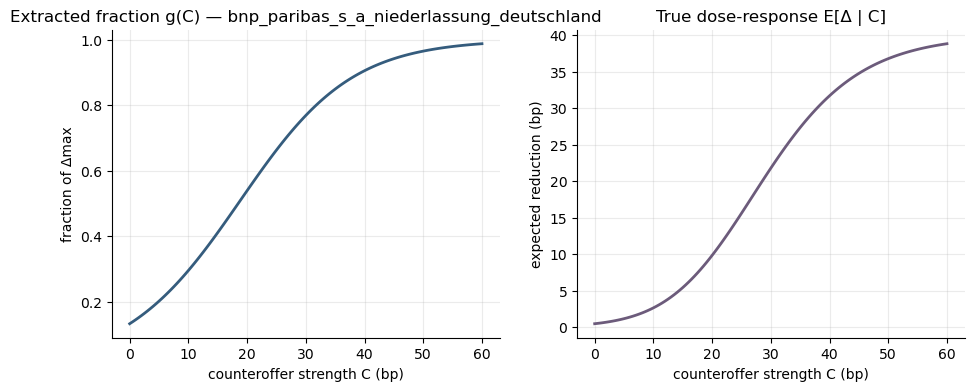

In [10]:
# Richards extracted-fraction curve and the implied E[Δ] dose-response for one bank.
b0 = sorted(panel.bank_id.unique())[0]; bp = bank_params[b0]
c_grid = np.linspace(0, 60, 121)
frac = negotiation.richards(c_grid, bp.c0, bp.k, bp.nu)
row = sim[sim.bank_id==b0].iloc[0:1]
mu = dgp.true_mu_grid(row, c_grid, bank_params)[0] * 100
fig, ax = plt.subplots(1,2, figsize=(11,4))
ax[0].plot(c_grid, frac, lw=2, color="#355c7d"); ax[0].set_title(f"Extracted fraction g(C) — {b0}")
ax[0].set_xlabel("counteroffer strength C (bp)"); ax[0].set_ylabel("fraction of Δmax")
ax[1].plot(c_grid, mu, lw=2, color="#6c5b7b"); ax[1].set_title("True dose-response E[Δ | C]")
ax[1].set_xlabel("counteroffer strength C (bp)"); ax[1].set_ylabel("expected reduction (bp)")
plt.show()

## 6. Product output — Top-5 ranking for one borrower

Two models compose the output: the initial-offer surface and the reduction hurdle model, combined by
Monte Carlo into a final-rate distribution. Banks are ranked by $Score_b = E[R^{final}_b] + \lambda\,SD(R^{final}_b)$
plus a thin-data penalty — the largest discount is **not** the best bank.

In [11]:
# Out-of-sample split by borrower (no leakage across the same borrower).
bids = profiles.borrower_id.unique().copy(); np.random.default_rng(RUN.seed).shuffle(bids)
train_ids = set(bids[:int(0.7*len(bids))])
train = sim[sim.borrower_id.isin(train_ids)]
test  = sim[~sim.borrower_id.isin(train_ids)]

model = product.ReductionHurdleModel().fit(train)
pred  = model.predict(test)
fin   = product.final_rate_distribution(test, pred)
full  = pd.concat([test.reset_index(drop=True), pred.reset_index(drop=True), fin.reset_index(drop=True)], axis=1)
ranked = product.rank_banks(full, lam=0.5, top_k=5, penalties=banks.data_density_penalty(bank_spreads))

one_id = ranked.borrower_id.iloc[0]
one = ranked[ranked.borrower_id==one_id]
print(f"Borrower {one_id}")
product.format_recommendation(one)

Borrower b1_000001


,Rank,Bank,Initial (median),Expected reduction,Likely reduction,P(Δ>0),Expected final,80% final CI
0,1,sparda_bank_muenchen_eg,3.09%,6.9 bp,14.5–18.5 bp,41%,3.02%,2.81–3.24%
1,2,psd_bank_nord_eg,3.18%,6.7 bp,14.3–18.2 bp,41%,3.12%,2.91–3.33%
2,3,sparda_bank_nuernberg_eg,3.2%,4.2 bp,15.9–17.5 bp,25%,3.16%,2.98–3.37%
3,4,frankfurter_sparkasse,3.75%,36.2 bp,35.1–39.3 bp,97%,3.39%,3.2–3.57%
4,5,open_account,3.92%,37.5 bp,35.8–39.3 bp,99%,3.55%,3.36–3.72%


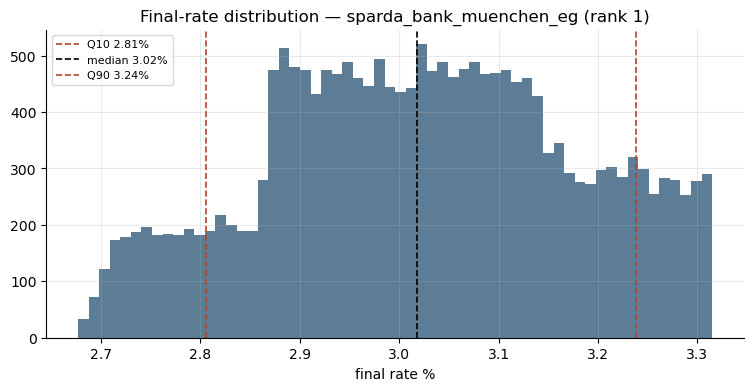

In [12]:
# Final-rate distribution for this borrower's recommended (rank-1) bank.
top = one.sort_values("rank").iloc[0]
from finanzfair.product import _sample_from_quantiles
g = np.random.default_rng(0)
ri = _sample_from_quantiles([top.r_initial_q10],[top.r_initial_q50],[top.r_initial_q90],20000,g)[0]
dp = np.clip(_sample_from_quantiles([top.delta_q10],[top.delta_q50],[top.delta_q90],20000,g)[0],0,None)
occur = g.random(20000) < top.p_reduction
rf = ri - np.where(occur, dp, 0.0)
fig, ax = plt.subplots()
ax.hist(rf, bins=60, color="#355c7d", alpha=0.8)
for q,c,l in [(top.final_q10,"#b4442e","Q10"),(top.final_q50,"k","median"),(top.final_q90,"#b4442e","Q90")]:
    ax.axvline(q, color=c, ls="--", lw=1.2, label=f"{l} {q:.2f}%")
ax.set_title(f"Final-rate distribution — {top.bank_id} (rank 1)"); ax.set_xlabel("final rate %")
ax.legend(fontsize=8); plt.show()

## 7. Evaluation — distributional quality & calibration

Factual metrics on the held-out borrowers. Calibration matters most for a consumer-facing financial
product: when we say *82% chance of a reduction*, it should happen ~82% of the time.

In [13]:
metrics = evaluate.summarize_reduction(test, pred)
pd.Series(metrics).round(4).to_frame("value")

,value
reduction_MAE,0.0368
pinball_q10,0.0319
pinball_q50,0.0235
pinball_q90,0.0058
Brier_p_pos,0.0907
LogLoss_p_pos,0.2639
ECE_p_pos,0.0109


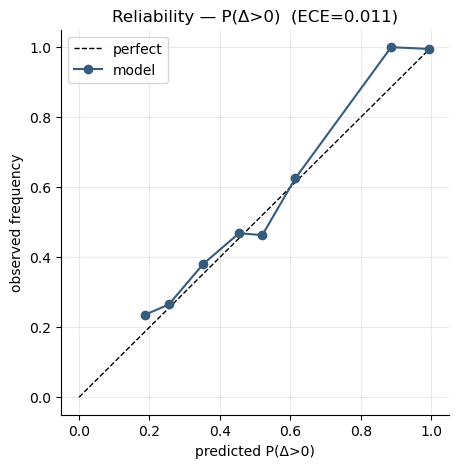

,bin,mean_pred,observed_freq,n
0,0.1-0.2,0.187,0.235,17
1,0.2-0.3,0.255,0.265,566
2,0.3-0.4,0.353,0.380,297
3,0.4-0.5,0.454,0.469,715
4,0.5-0.6,0.520,0.463,639
5,0.6-0.7,0.614,0.625,16
6,0.8-0.9,0.886,1.000,4
7,0.9-1.0,0.994,0.995,3746


In [14]:
y_pos = (test.true_delta.to_numpy() > 1e-6).astype(int)
rel = evaluate.reliability_table(y_pos, pred.p_reduction.to_numpy(), bins=10)
fig, ax = plt.subplots(figsize=(5,5))
ax.plot([0,1],[0,1],"k--",lw=1,label="perfect")
ax.plot(rel.mean_pred, rel.observed_freq, "o-", color="#355c7d", label="model")
ax.set_xlabel("predicted P(Δ>0)"); ax.set_ylabel("observed frequency")
ax.set_title(f"Reliability — P(Δ>0)  (ECE={metrics['ECE_p_pos']:.3f})"); ax.legend(); plt.show()
rel.round(3)

## 8. Counterfactual & selection-bias stress test

**Secondary research question:** how much does selection bias in the availability/quality of competing
offers distort ML estimates of negotiation potential? Strong borrowers get stronger counteroffers, so
$X\!\to\!C$ and $X\!\to\!R^{final}$ simultaneously. We compare a **counteroffer-aware** model to a **naive**
model (no counteroffer feature) across bias levels $\theta$, using two metrics only computable because the
synthetic layer provides counterfactual truth: **MISE** (did we recover the whole dose-response
$\mu(c,x)$?) and **policy error** in bp (does the ranking send the borrower to the truly best bank?).
A model can look fine on factual outcomes yet fail both — exactly the failure the causal-pricing paper warns about.

> **Reading the result.** MISE is the operative signal here: the naive model, blind to the real counteroffer
> feature, cannot reconstruct $\mu(c,x)$ at any bias level, while the aware model recovers it increasingly well
> as the counteroffer signal strengthens. Policy error is ~0 for both because, with these real spreads, the
> lowest-*initial* bank is also the best *final* bank — the initial level dominates the ranking — so both models
> route the borrower to the same (correct) bank. That itself is the headline product insight: **largest discount ≠ best bank.**

                    MISE           policy_error_bp      
model counteroffer-aware  naive counteroffer-aware naive
theta                                                   
0.0                1.920  2.123                0.0   0.0
2.5                1.789  2.117                0.0   0.0
5.0                1.660  2.113                0.0   0.0
10.0               0.535  2.031                0.0   0.0
20.0               0.053  1.615                0.0   0.0


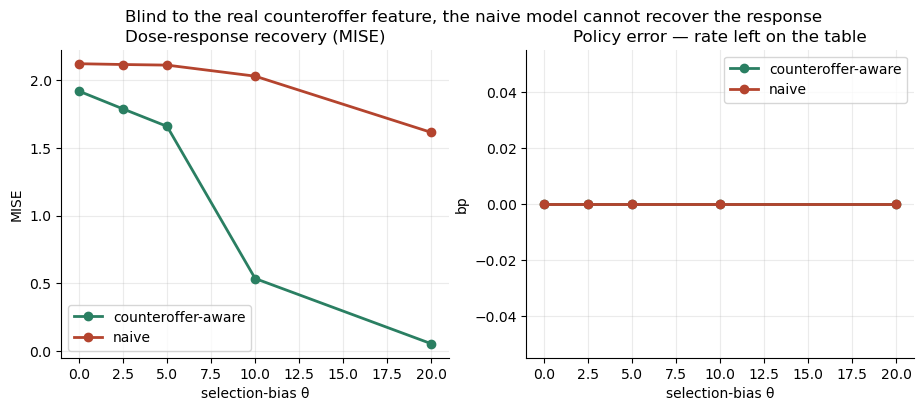

In [15]:
c_grid = np.linspace(0, 50, 26)
rows = []
for th in [0.0, 2.5, 5.0, 10.0, 20.0]:
    ic = negotiation.apply_selection_bias(initial, profiles, theta=th, seed=RUN.seed)
    pn = ic.merge(profiles[["borrower_id","LTV","DTI","gross_household_income"]], on="borrower_id")
    dg = negotiation.NegotiationDGP(family="richards", selection_bias=th, seed=RUN.seed)
    bpm = dg.sample_bank_params(sorted(pn.bank_id.unique()))
    s = dg.simulate(pn, bpm)
    tr = s[s.borrower_id.isin(train_ids)]; teh = s[~s.borrower_id.isin(train_ids)].copy()
    mu_true = dg.true_mu_grid(teh, c_grid, bpm)
    # True expected final per (borrower,bank) from known counterfactual E[Δ].
    teh["true_final"] = teh["r_initial_q50"] - teh["true_mu_delta"]
    true_best = teh.groupby("borrower_id")["true_final"].transform("min")
    for aware in (True, False):
        mdl = product.ReductionHurdleModel(use_counteroffer=aware).fit(tr)
        mise = evaluate.mise(mu_true, mdl.predict_mu(teh, c_grid), c_grid)
        pr = mdl.predict(teh)
        teh["_pred_final"] = teh["r_initial_q50"] - pr["expected_delta"].values
        pick = teh.loc[teh.groupby("borrower_id")["_pred_final"].idxmin()]  # model's chosen bank
        chosen_true = pick["true_final"].values
        best_true = teh.groupby("borrower_id")["true_final"].min().loc[pick["borrower_id"]].values
        pe_bp = float(np.mean(chosen_true - best_true) * 100)
        rows.append({"theta": th, "model": "counteroffer-aware" if aware else "naive",
                     "MISE": mise, "policy_error_bp": pe_bp})
bias = pd.DataFrame(rows)
print(bias.pivot(index="theta", columns="model", values=["MISE","policy_error_bp"]).round(3))
fig, ax = plt.subplots(1,2, figsize=(11,4))
for col,c in [("counteroffer-aware","#2a7f62"),("naive","#b4442e")]:
    p=bias[bias.model==col]
    ax[0].plot(p.theta, p.MISE, "o-", label=col, color=c, lw=2)
    ax[1].plot(p.theta, p.policy_error_bp, "o-", label=col, color=c, lw=2)
ax[0].set_title("Dose-response recovery (MISE)"); ax[0].set_xlabel("selection-bias θ"); ax[0].set_ylabel("MISE")
ax[1].set_title("Policy error — rate left on the table"); ax[1].set_xlabel("selection-bias θ"); ax[1].set_ylabel("bp")
ax[0].legend(); ax[1].legend()
plt.suptitle("Blind to the real counteroffer feature, the naive model cannot recover the response"); plt.show()

## 9. Ablation — does each real data layer add value?

Build the reduction model on increasing feature sets and measure held-out quality. This isolates the
contribution of each real data layer (section 55).

In [16]:
abl = []
layer_feats = {
    "M0 borrower+loan": ["credit_quality","LTV","DTI","log_income"],
    "M1 +bank":         ["credit_quality","LTV","DTI","log_income","bank_code"],
    "M2 +Δmax(market/surface)": ["credit_quality","LTV","DTI","log_income","bank_code","delta_max"],
    "M3 +competition":  ["credit_quality","LTV","DTI","log_income","bank_code","delta_max","counteroffer_gap_bp"],
}
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
def design(p, feats):
    X = pd.DataFrame(index=p.index)
    X["counteroffer_gap_bp"]=p["counteroffer_gap_bp"]; X["delta_max"]=p["delta_max"]
    X["credit_quality"]=p["credit_quality"]; X["LTV"]=p["LTV"]; X["DTI"]=p["DTI"]
    X["log_income"]=np.log(p["gross_household_income"].clip(lower=1)); X["bank_code"]=p["bank_id"].astype("category").cat.codes
    return X[feats]
for name, feats in layer_feats.items():
    Xtr, Xte = design(train, feats), design(test, feats)
    ytr = train.true_delta.to_numpy(); yte = test.true_delta.to_numpy()
    pos = ytr>1e-6
    clf = HistGradientBoostingClassifier(max_iter=250, max_depth=4, min_samples_leaf=80, random_state=7).fit(Xtr, pos.astype(int))
    reg = HistGradientBoostingRegressor(max_iter=250, max_depth=4, min_samples_leaf=60, random_state=7).fit(Xtr[pos], ytr[pos])
    exp_delta = clf.predict_proba(Xte)[:,1]*np.clip(reg.predict(Xte),0,None)
    abl.append({"model":name, "reduction_MAE_bp": evaluate.mae(yte, exp_delta)*100,
                "Brier_p>0": evaluate.brier_score((yte>1e-6).astype(int), clf.predict_proba(Xte)[:,1])})
pd.DataFrame(abl).round(3)

,model,reduction_MAE_bp,Brier_p>0
0,M0 borrower+loan,14.141,0.175
1,M1 +bank,4.858,0.091
2,M2 +Δmax(market/surface),3.683,0.092
3,M3 +competition,3.672,0.091


## 10. Caveats & roadmap

- **Synthetic negotiation ≠ evidence.** The semi-synthetic layer proves an estimator can recover a *known*
  response; it does not prove a real German bank follows it. It is replaced/calibrated by real
  user-reported outcomes in V2 (`label_source` ∈ {user_reported, verified_offer, verified_final_offer}).
- **Advertised rate ≠ bank floor.** Scraped minimums are observable references, not internal floors.
- **Cross-country.** HMDA/NSMO/Freddie are research priors (spread *shape* + dispersion), never German
  labels; the level comes from real ECB/Bundesbank German series. PHF/HFCS (German/EU borrowers) and
  Freddie Mac load via `finanzfair.ingest.microdata` once you drop the files in `data/external/`.
- **GDPR.** Store a random UUID, coarse region, income band, employment category, SCHUFA band and loan
  parameters — not names, IBANs, exact addresses or full credit reports.
- **Reproducibility.** Every simulated row carries `simulation_version`, `synthetic_version`, `dgp_family`,
  `selection_bias_theta` and the run seed.

**Next:** wire PHF/HFCS German borrower distribution → recalibrate the surface level to Bundesbank
fixation-bucket dispersion → collect real feedback → hierarchical bank-level partial pooling (V2) →
causal dose-response once identification is defensible (V3).